# 01 - Exploratory data analysis

Goal: understand the data before building anything. NumPy + matplotlib only.

Questions answered here:
1. How big is the data and how imbalanced are the labels?
2. Which columns are mostly missing, constant or just administrative?
3. Which columns look continuous vs categorical?
4. Which columns contain special codes (7/9/77/99/...) that really mean *missing*?
5. Which features are most correlated with the label?

In [1]:
import numpy as np
import matplotlib.pyplot as plt

d = np.load("../data/cache.npz")  # created by make_cache.py
x, x_test, y = d["x"], d["x_test"], d["y"]
y01 = (y == 1).astype(int)  # labels in {0, 1}

# Column names come from the CSV header (first column 'Id' is not part of x)
with open("../data/dataset/x_train.csv") as f:
    names = np.array(f.readline().strip().split(",")[1:])
assert len(names) == x.shape[1]

print("x_train:", x.shape, " x_test:", x_test.shape)

x_train: (328135, 321)  x_test: (109379, 321)


## 1. Labels

In [2]:
print("positives (heart disease):", y01.sum(), f"({y01.mean():.2%})")
print("negatives:", (1 - y01).sum())
print("Accuracy of always predicting 'no disease':", f"{1 - y01.mean():.2%}")
print("-> accuracy is misleading, use F1 and tune the decision threshold.")

positives (heart disease): 28975 (8.83%)
negatives: 299160
Accuracy of always predicting 'no disease': 91.17%
-> accuracy is misleading, use F1 and tune the decision threshold.


## 2. Missing values

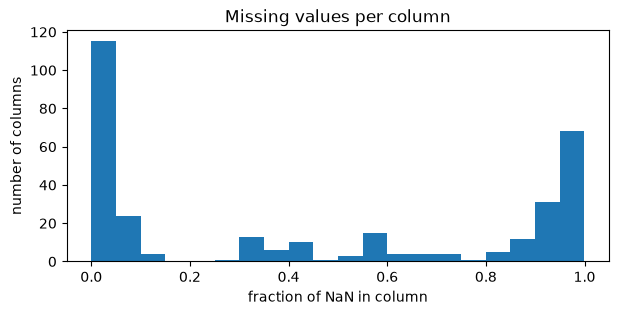

columns with NaN rate > 0.00: 239
columns with NaN rate > 0.20: 178
columns with NaN rate > 0.50: 147
columns with NaN rate > 0.80: 116
columns with NaN rate > 0.95: 68


In [3]:
nan_rate = np.isnan(x).mean(axis=0)

plt.figure(figsize=(7, 3))
plt.hist(nan_rate, bins=20)
plt.xlabel("fraction of NaN in column")
plt.ylabel("number of columns")
plt.title("Missing values per column")
plt.show()

for t in [0.0, 0.2, 0.5, 0.8, 0.95]:
    print(f"columns with NaN rate > {t:.2f}: {(nan_rate > t).sum()}")

## 3. Constant / administrative columns

In [4]:
n_unique = np.array([len(np.unique(c[~np.isnan(c)])) for c in x.T])

constant = np.where(n_unique <= 1)[0]
print("constant columns:", list(names[constant]))

# Administrative columns: interview dates, IDs, sampling info (no medical meaning)
admin_names = ["FMONTH", "IDATE", "IMONTH", "IDAY", "IYEAR", "DISPCODE", "SEQNO", "_PSU"]
admin = [i for i, n in enumerate(names) if n in admin_names]
print("administrative columns:", list(names[admin]))

constant columns: [np.str_('CTELENUM'), np.str_('COLGHOUS'), np.str_('STATERES'), np.str_('CTELNUM1'), np.str_('CELLFON2'), np.str_('CCLGHOUS')]
administrative columns: [np.str_('FMONTH'), np.str_('IDATE'), np.str_('IMONTH'), np.str_('IDAY'), np.str_('IYEAR'), np.str_('DISPCODE'), np.str_('SEQNO'), np.str_('_PSU')]


## 4. Column types (continuous vs categorical)

Rough rule based on the number of distinct values (the BRFSS codebook gives the exact types).

In [5]:
binary = np.where(n_unique == 2)[0]
categorical = np.where((n_unique > 2) & (n_unique <= 10))[0]
medium = np.where((n_unique > 10) & (n_unique <= 50))[0]
continuous = np.where(n_unique > 50)[0]
print("binary (2 values):", len(binary))
print("few values (3-10), likely categorical:", len(categorical))
print("11-50 values, ambiguous:", len(medium))
print("more than 50 values, likely continuous:", len(continuous))
print("\nExamples of likely continuous columns:", list(names[continuous][:15]))

binary (2 values): 14
few values (3-10), likely categorical: 199
11-50 values, ambiguous: 39
more than 50 values, likely continuous: 63

Examples of likely continuous columns: [np.str_('_STATE'), np.str_('IDATE'), np.str_('SEQNO'), np.str_('_PSU'), np.str_('DIABAGE2'), np.str_('WEIGHT2'), np.str_('HEIGHT3'), np.str_('MAXDRNKS'), np.str_('FRUITJU1'), np.str_('FRUIT1'), np.str_('FVBEANS'), np.str_('FVGREEN'), np.str_('FVORANG'), np.str_('VEGETAB1'), np.str_('EXRACT11')]


## 5. Special codes

In BRFSS, codes like 7 / 9 / 77 / 99 / 777 / 999 usually mean *don't know / refused* and must be turned into NaN. Look at the value counts of a column to spot them.

In [6]:
def show_values(col_name, top=12):
    """Print the most frequent values of a column and the positive rate for each."""
    j = list(names).index(col_name)
    c = x[:, j]
    vals, counts = np.unique(c[~np.isnan(c)], return_counts=True)
    order = np.argsort(-counts)[:top]
    print(f"{col_name}: {np.isnan(c).mean():.1%} NaN, {len(vals)} distinct values")
    for v, n in zip(vals[order], counts[order]):
        print(f"  value {v:>8}: n={n:>7}  positive rate={y01[c == v].mean():.3f}")

for col in ["GENHLTH", "PHYSHLTH", "BPHIGH4", "_AGEG5YR", "_BMI5"]:
    if col in names:
        show_values(col)
        print()

GENHLTH: 0.0% NaN, 7 distinct values
  value      2.0: n= 108089  positive rate=0.042
  value      3.0: n= 101880  positive rate=0.091
  value      1.0: n=  56937  positive rate=0.021
  value      4.0: n=  43349  positive rate=0.193
  value      5.0: n=  16992  positive rate=0.319
  value      7.0: n=    562  positive rate=0.171
  value      9.0: n=    324  positive rate=0.142

PHYSHLTH: 0.0% NaN, 33 distinct values
  value     88.0: n= 204264  positive rate=0.059
  value     30.0: n=  25233  positive rate=0.229
  value      2.0: n=  18182  positive rate=0.072
  value      1.0: n=  13676  positive rate=0.050
  value      3.0: n=  10553  positive rate=0.091
  value      5.0: n=   9207  positive rate=0.110
  value     10.0: n=   6754  positive rate=0.153
  value     15.0: n=   6150  positive rate=0.187
  value      7.0: n=   5892  positive rate=0.102
  value      4.0: n=   5672  positive rate=0.108
  value     77.0: n=   5587  positive rate=0.163
  value     20.0: n=   4033  positive rat

For example, `GENHLTH` has values 1-5 plus 7 and 9 (don't know / refused), and `PHYSHLTH` uses 88 for *none* and 77/99 for unknown. These rules are applied in `preprocess.py`.

## 6. Which features correlate with the label?

In [7]:
corr = np.zeros(x.shape[1])
for j in range(x.shape[1]):
    m = ~np.isnan(x[:, j])
    if m.sum() > 100 and x[m, j].std() > 0:
        corr[j] = np.corrcoef(x[m, j], y01[m])[0, 1]

top = np.argsort(-np.abs(corr))[:20]
for j in top:
    print(f"{names[j]:<12} corr={corr[j]:+.3f}  NaN={nan_rate[j]:.1%}")

c:\Users\badis\project\ML\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\badis\project\ML\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


GENHLTH      corr=+0.244  NaN=0.0%
CVDASPRN     corr=-0.228  NaN=95.7%
_AGE80       corr=+0.225  NaN=0.0%
_AGEG5YR     corr=+0.219  NaN=0.0%
EMPLOY1      corr=+0.207  NaN=0.0%
_AGE_G       corr=+0.207  NaN=0.0%
BPHIGH4      corr=-0.205  NaN=0.0%
_HCVU651     corr=+0.196  NaN=0.0%
_AGE65YR     corr=+0.185  NaN=0.0%
_RFHLTH      corr=+0.172  NaN=0.0%
_RFHYPE5     corr=+0.171  NaN=0.0%
_DRDXAR1     corr=-0.168  NaN=0.6%
DIABETE3     corr=-0.161  NaN=0.0%
DRADVISE     corr=-0.143  NaN=90.7%
USEEQUIP     corr=-0.135  NaN=2.4%
DIFFWALK     corr=-0.134  NaN=2.8%
HAVARTH3     corr=-0.122  NaN=0.0%
ARTTODAY     corr=+0.120  NaN=95.6%
ASERVIST     corr=-0.118  NaN=99.9%
QLACTLM2     corr=-0.115  NaN=2.1%


Note: the correlation is computed on raw codes (including special codes like 7/9), so it is only a rough first ranking.

## 7. Positive rate by value (one feature)

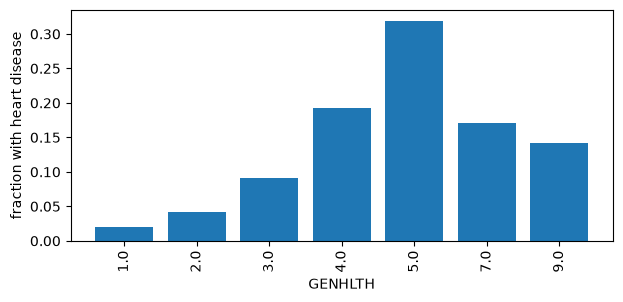

In [8]:
col = names[top[0]]  # change to any column name
j = list(names).index(col)
c = x[:, j]
vals = np.unique(c[~np.isnan(c)])[:30]
rates = [y01[c == v].mean() for v in vals]

plt.figure(figsize=(7, 3))
plt.bar(range(len(vals)), rates)
plt.xticks(range(len(vals)), vals, rotation=90)
plt.xlabel(col)
plt.ylabel("fraction with heart disease")
plt.show()

## 8. Summary: columns to drop

Candidate columns to drop, as done in `preprocess.py`.

In [9]:
drop_nan = np.where(nan_rate > 0.8)[0]
drop = sorted(set(drop_nan) | set(constant) | set(admin))
print(f"candidate columns to drop: {len(drop)} / {x.shape[1]}")
print(f"  >80% NaN: {len(drop_nan)}, constant: {len(constant)}, administrative: {len(admin)}")
print(f"remaining: {x.shape[1] - len(drop)}")

candidate columns to drop: 128 / 321
  >80% NaN: 116, constant: 6, administrative: 8
remaining: 193
